# 03. Проверенные external-negatives: аудит, разделение и отказ

Пользователь подтвердил просмотр оставшихся изображений. Это подтверждение записано в manifest,
но технические конфликты с положительным набором дополнительно исключаются.
Negative POI не становятся классом unknown и не добавляются в галерею.
Backbone MobileNetV3-Small, положительные splits и train-галерея сохранены.


In [1]:
from pathlib import Path
import sys,json
import numpy as np
import pandas as pd
from IPython.display import display,Markdown,Image as DisplayImage
ROOT=Path.cwd().resolve()
if not (ROOT/'config/wikimedia_negatives.csv').exists():ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from src.poi_baseline import sha256_file,POIVerifier
from src.negative_baseline import recalibrate_with_negatives
OUTPUT=ROOT/'models/baseline_mobilenetv3_negatives'
manifest=pd.read_csv(ROOT/'data/annotations/negative_manifest.csv',keep_default_na=False)
summary=json.loads((ROOT/'reports/negatives/dataset_summary.json').read_text())
display(pd.Series(summary))


audit_records                                                       1151
existing_images                                                     1149
removed_by_user                                                        2
unreadable                                                             0
positive_overlap_candidates                                            3
exact_duplicate_excluded                                               0
released_images                                                     1146
split_counts                                   {'val': 573, 'test': 573}
split_poi_counts                                 {'val': 13, 'test': 12}
unknown_authors                                                        5
unknown_licences                                                       0
user_review_confirmed                                               True
seed                                                                  42
split_method                       disjoint_POI_and

## 1. Происхождение, подтверждённые метки и исключения

`source_poi_id` обозначает посторонний объект и не является целевым классом.
Физически удалённые файлы сохраняются в аудите как rejected / removed_by_user.
Признаки source/author/licence и исходные artist/license URL сохранены.
Сравнение с положительными фото: SHA-256, Commons-ID, pHash и фиксированные кропы.
Потенциальные пересечения исключены консервативно; это не доказательство ошибочной ручной проверки.


images
source_poi_id                             label_status exclusion_reason                  
moscow/aeroport/petrovsky_palace          verified                                     50
moscow/begovoy/moscow_hippodrome          verified                                     50
moscow/donskoy/shukhov_tower              verified                                     50
moscow/dorogomilovo/hotel_ukraina         verified                                     50
moscow/dorogomilovo/triumphal_arch        rejected     removed_by_user                  2
                                          verified                                     48
moscow/izmaylovo/izmaylovo_ferris_wheel   verified                                     13
moscow/krasnoselsky/kazansky_terminal     verified                                     50
moscow/krasnoselsky/leningradsky_terminal verified                                     50
moscow/levoberezhny/north_river_terminal  verified                                     50
moscow/meshchansky/russian_army_theatre   verified                                     50
moscow/ostankinskiy/azerbaijan_pavilion   verified                                     50
moscow/ostankinskiy/belarus_pavilion      verified                                     50
moscow/ostankinskiy/floriculture_pavilion verified                                     50
moscow/ostankinskiy/golden_spike_fountain verified                                     50
moscow/ostankinskiy/karelia_pavilion      verified                                     40
moscow/ostankinskiy/transport_pavilion    verified                                     37
moscow/ostankinskiy/ukraine_pavilion      verified                                     50
moscow/ostankinskiy/uzbekistan_pavilion   verified                                     50
moscow/presnensky/pekin_hotel             verified                                     43
moscow/tverskoy/four_seasons              needs_review positive_overlap_candidate       2
                                          verified                                     48
moscow/tverskoy/moscow_city_hall          verified                                     50
moscow/tverskoy/moscow_manege             verified                                     50
moscow/tverskoy/ritz_carlton              needs_review positive_overlap_candidate       1
                                          verified                                     30
moscow/tverskoy/savvinskoye_podvorie      verified                                     37
moscow/yakimanka/gorky_park_main_portal   verified                                     50

,image_id,source_poi_id,source,author,licence,label_status
0,neg_c8f21f31265e3a54,moscow/aeroport/petrovsky_palace,wikimedia_commons,Osazemen,CC BY-SA 4.0,verified
1,neg_006e50474a93d65d,moscow/aeroport/petrovsky_palace,wikimedia_commons,Osazemen,CC BY-SA 4.0,verified
2,neg_7bc6f2c1530660d5,moscow/aeroport/petrovsky_palace,wikimedia_commons,Osazemen,CC BY-SA 4.0,verified
3,neg_90a779d670d262cf,moscow/aeroport/petrovsky_palace,wikimedia_commons,Osazemen,CC BY-SA 4.0,verified
4,neg_19d481df07a03940,moscow/aeroport/petrovsky_palace,wikimedia_commons,Al Shipilin,GFDL,verified


,image_id,file_path,city,district,source_poi_id,poi_id,dataset_role,source,author,author_raw,...,readable,sha256,perceptual_hash,width,height,duplicate_group,split_group,split,active,exclusion_reason
0,neg_5ff1daf766855ac0,data/raw/wikimedia_negatives/moscow/tverskoy/f...,moscow,tverskoy,moscow/tverskoy/four_seasons,,external_negative,wikimedia_commons,Sergey Korovkin 84,"<a rel=""mw:WikiLink"" href=""https://commons.wik...",...,True,14449aee0b87dfe40507e03bae6209e1063dc30680fa17...,55c595d71f134461,4928,3264,dup_neg_5ff1daf766855ac0,neg_group_neg_08b44e37b7838ad3,,False,positive_overlap_candidate
1,neg_d2097195f1f74793,data/raw/wikimedia_negatives/moscow/tverskoy/f...,moscow,tverskoy,moscow/tverskoy/four_seasons,,external_negative,wikimedia_commons,Sergey Korovkin 84,"<a href=""//commons.wikimedia.org/w/index.php?t...",...,True,180cbaa59d2e4402b37b6f8611b287cfaac80a49b4b46b...,12f7b9d6a04ccf02,4928,3264,dup_neg_d2097195f1f74793,neg_group_neg_08b44e37b7838ad3,,False,positive_overlap_candidate
2,neg_5f4b5704036c74a4,data/raw/wikimedia_negatives/moscow/tverskoy/r...,moscow,tverskoy,moscow/tverskoy/ritz_carlton,,external_negative,wikimedia_commons,Богдан Митронов-Слоб…,"<a rel=""nofollow"" class=""external text"" href=""...",...,True,eeb6fd8c6b320a2377360562c158b85fc899e319ca731d...,0198c25e68e53efa,4434,3264,dup_neg_5f4b5704036c74a4,neg_group_neg_012250c3c1b2aba2,,False,positive_overlap_candidate


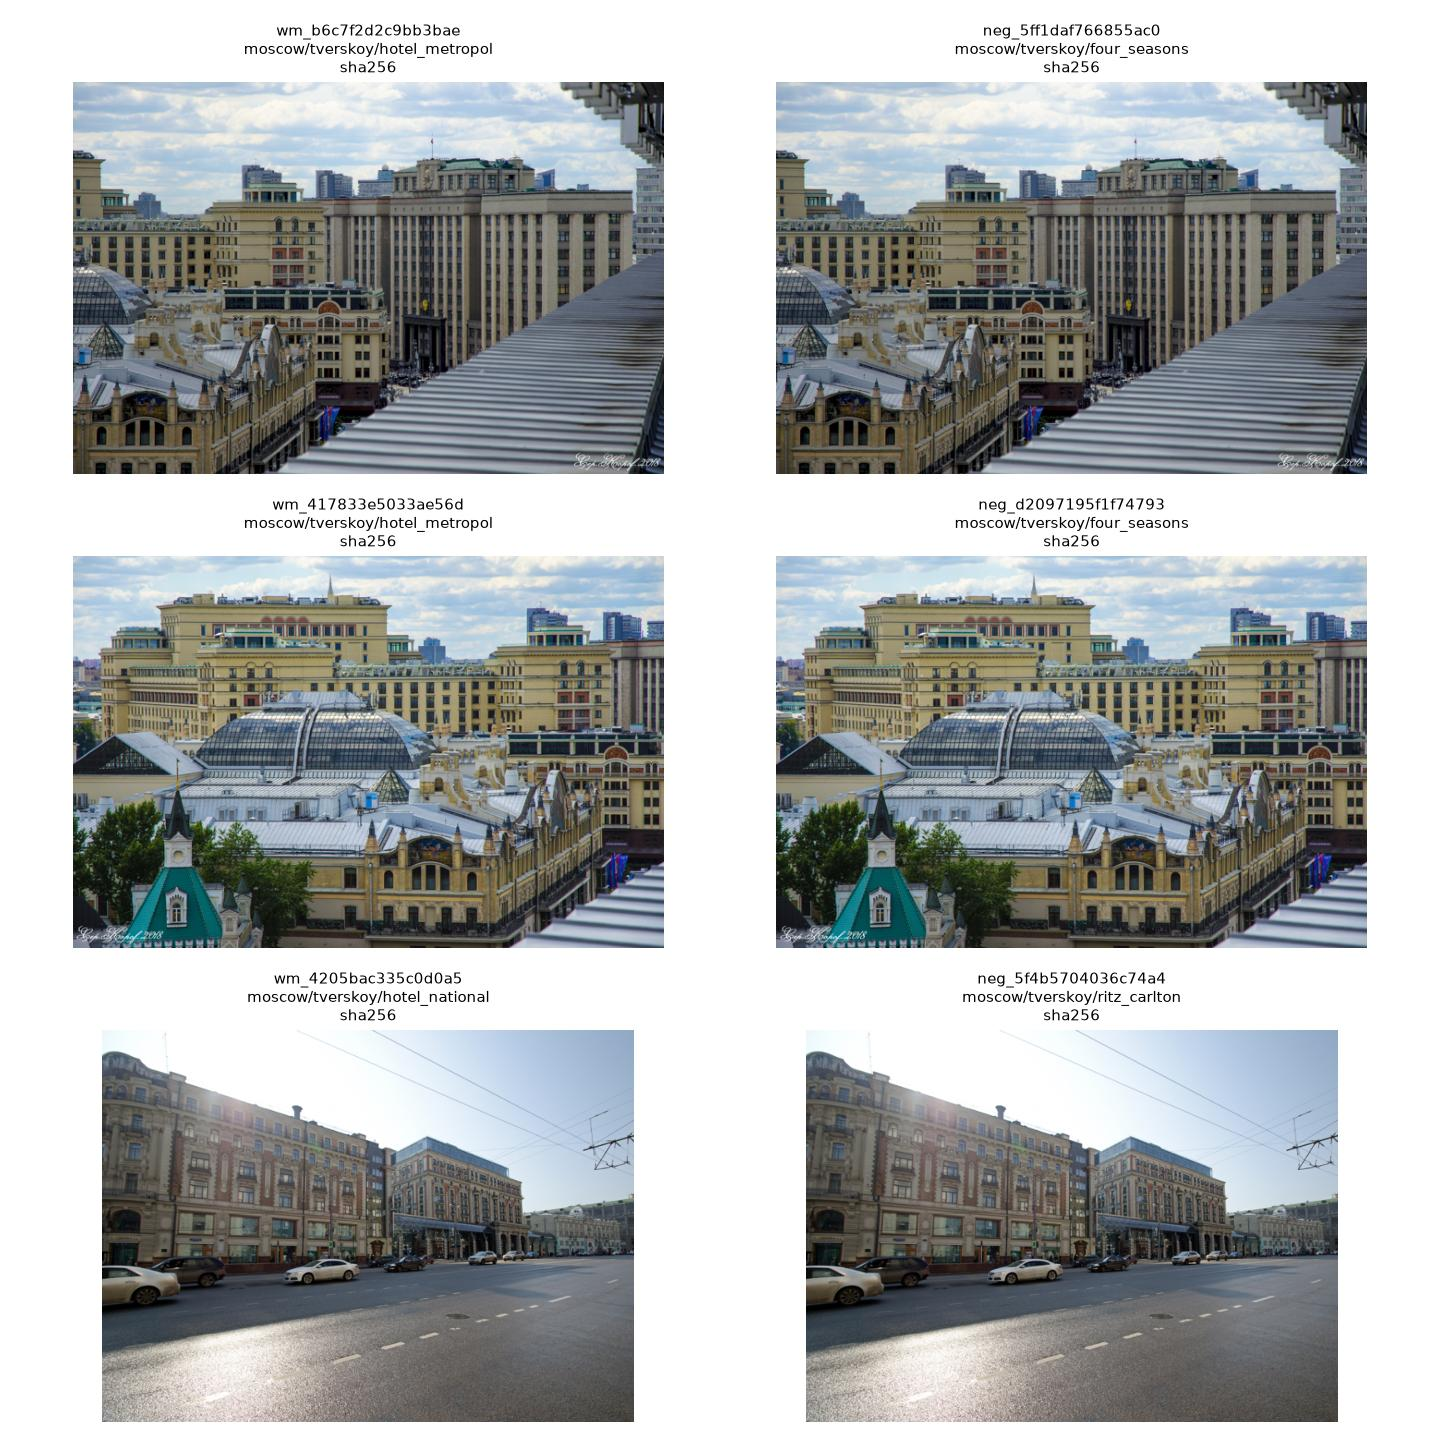

In [2]:
display(manifest.groupby(['source_poi_id','label_status','exclusion_reason'],dropna=False).size().rename('images').to_frame())
display(manifest[['image_id','source_poi_id','source','author','licence','label_status']].head())
display(pd.read_csv(ROOT/'data/annotations/negative_review_queue.csv',keep_default_na=False))
overlap_sheet=ROOT/'reports/negatives/positive_overlap_examples.jpg'
if overlap_sheet.exists():display(DisplayImage(filename=str(overlap_sheet)))


## 2. Negative-val и negative-test

SEED=42. Целевое соотношение 50/50 приближается с учётом целых POI и связей копий.
Один source POI, серия одного объекта и группа дубликатов не попадают в обе выборки.
Распределения negative_type могут отличаться: при единственном объекте типа
невозможно представить его в обоих splits без пересечения идентичности.


In [3]:
negatives={s:pd.read_csv(ROOT/f'data/annotations/negative_{s}.csv',keep_default_na=False) for s in ['val','test']}
for field in ['image_id','sha256','commons_file_id','source_poi_id','duplicate_group','split_group']:
    assert not (set(negatives['val'][field])-{''})&(set(negatives['test'][field])-{''}),field
display(pd.crosstab(manifest.loc[manifest.active,'negative_type'],manifest.loc[manifest.active,'split']))
print('Negative POI val:', sorted(negatives['val'].source_poi_id.unique()))
print('Negative POI test:', sorted(negatives['test'].source_poi_id.unique()))


split,test,val
negative_type,,
similar_arch,48,50
similar_classical_building,100,100
similar_decorated_building,50,0
similar_ferris_wheel,0,13
similar_fountain,0,50
similar_hotel,98,73
similar_mansion,50,87
similar_pavilion,177,150
similar_theatre,0,50


Negative POI val: ['moscow/begovoy/moscow_hippodrome', 'moscow/izmaylovo/izmaylovo_ferris_wheel', 'moscow/levoberezhny/north_river_terminal', 'moscow/meshchansky/russian_army_theatre', 'moscow/ostankinskiy/floriculture_pavilion', 'moscow/ostankinskiy/golden_spike_fountain', 'moscow/ostankinskiy/ukraine_pavilion', 'moscow/ostankinskiy/uzbekistan_pavilion', 'moscow/presnensky/pekin_hotel', 'moscow/tverskoy/moscow_city_hall', 'moscow/tverskoy/ritz_carlton', 'moscow/tverskoy/savvinskoye_podvorie', 'moscow/yakimanka/gorky_park_main_portal']
Negative POI test: ['moscow/aeroport/petrovsky_palace', 'moscow/donskoy/shukhov_tower', 'moscow/dorogomilovo/hotel_ukraina', 'moscow/dorogomilovo/triumphal_arch', 'moscow/krasnoselsky/kazansky_terminal', 'moscow/krasnoselsky/leningradsky_terminal', 'moscow/ostankinskiy/azerbaijan_pavilion', 'moscow/ostankinskiy/belarus_pavilion', 'moscow/ostankinskiy/karelia_pavilion', 'moscow/ostankinskiy/transport_pavilion', 'moscow/tverskoy/four_seasons', 'moscow/tver

## 3. Новая калибровка без дообучения

Только positive-val + negative-val. Цели: known-wrong FAR ≤1%, hard-wrong FAR ≤5%,
external any-POI FAR ≤1%. Из допустимых порогов выбирается максимальный true accept.
External фото считается ошибочно принятым, если подтверждается хотя бы один из поддерживаемых POI.
Это строже средней ошибки по всем парам «фото — цель».
Test оценивается после фиксации порогов; его результаты не меняют пороги.
Повторный запуск читает зафиксированный выпуск, проверяя его артефакты и текущие negative splits.


In [4]:
if not (OUTPUT/'metadata.json').exists():
    policy,metrics=recalibrate_with_negatives(ROOT,ROOT/'models/baseline_mobilenetv3',OUTPUT)
else:
    meta=json.loads((OUTPUT/'metadata.json').read_text())
    for name,digest in meta['artifact_sha256'].items():assert sha256_file(OUTPUT/name)==digest,name
    for split,digest in meta['negative_split_sha256'].items():assert sha256_file(ROOT/f'data/annotations/negative_{split}.csv')==digest
    policy=json.loads((OUTPUT/'rejection_policy.json').read_text())
    metrics=json.loads((OUTPUT/'metrics.json').read_text())
display(pd.Series(policy))
comparison=[]
for name in ['val','test']:
    old=json.loads((ROOT/'models/baseline_mobilenetv3/metrics.json').read_text())[name]
    comparison.append({'split':name,'old_true_accept':old['true_accept_rate'],'new_true_accept':metrics[name]['true_accept_rate'],
                       'new_hard_wrong_far':metrics[name]['hard_wrong_far'],'external_any_poi_far':metrics[f'negative_{name}']['any_poi_far']})
display(pd.DataFrame(comparison))


score_threshold                                                         0.839531
margin_threshold                                                        0.058894
true_accept_rate                                                        0.317881
known_wrong_far                                                              0.0
hard_wrong_far                                                               0.0
tp                                                                            48
fp                                                                             0
external_any_poi_far                                                    0.008726
external_false_accepts                                                         5
calibration_split                                                            val
target_known_wrong_far                                                      0.01
target_hard_wrong_far                                                       0.05
negative_scope              

,split,old_true_accept,new_true_accept,new_hard_wrong_far,external_any_poi_far
0,val,0.635762,0.317881,0.0,0.008726
1,test,0.664384,0.253425,0.0,0.008726


## 4. Ошибки отказа на independent negative-test

Все исходные фотографии остаются на месте. Результаты предназначены для диагностики;
после просмотра ошибок test не используют для ручной настройки порогов текущего выпуска.
Набор содержит прежде всего достопримечательности Commons; обычная мобильная съёмка требует отдельной проверки.


,image_id,source_poi_id,predicted_poi_id,score,margin
35,neg_0f736daa050cdaea,moscow/tverskoy/moscow_manege,moscow/ostankinskiy/cosmos,0.857761,0.359052
254,neg_733ef1ddc6271c67,moscow/dorogomilovo/triumphal_arch,moscow/ostankinskiy/main_entrance,0.900620,0.060760
255,neg_73452575526bb24b,moscow/dorogomilovo/triumphal_arch,moscow/ostankinskiy/main_entrance,0.853207,0.060444
561,neg_fb7c057b049b9e54,moscow/krasnoselsky/kazansky_terminal,moscow/ostankinskiy/central_pavilion,0.882147,0.082356
567,neg_fde1205f5dfbd3f3,moscow/krasnoselsky/kazansky_terminal,moscow/ostankinskiy/central_pavilion,0.887526,0.079546


,group_by,group,images,false_accepts,any_poi_far
0,negative_type,similar_arch,48,2,0.041667
1,negative_type,similar_classical_building,100,1,0.010000
2,negative_type,similar_decorated_building,50,2,0.040000
3,negative_type,similar_hotel,98,0,0.000000
4,negative_type,similar_mansion,50,0,0.000000
5,negative_type,similar_pavilion,177,0,0.000000
6,negative_type,similar_tower,50,0,0.000000
7,source_poi_id,moscow/aeroport/petrovsky_palace,50,0,0.000000
8,source_poi_id,moscow/donskoy/shukhov_tower,50,0,0.000000
9,source_poi_id,moscow/dorogomilovo/hotel_ukraina,50,0,0.000000


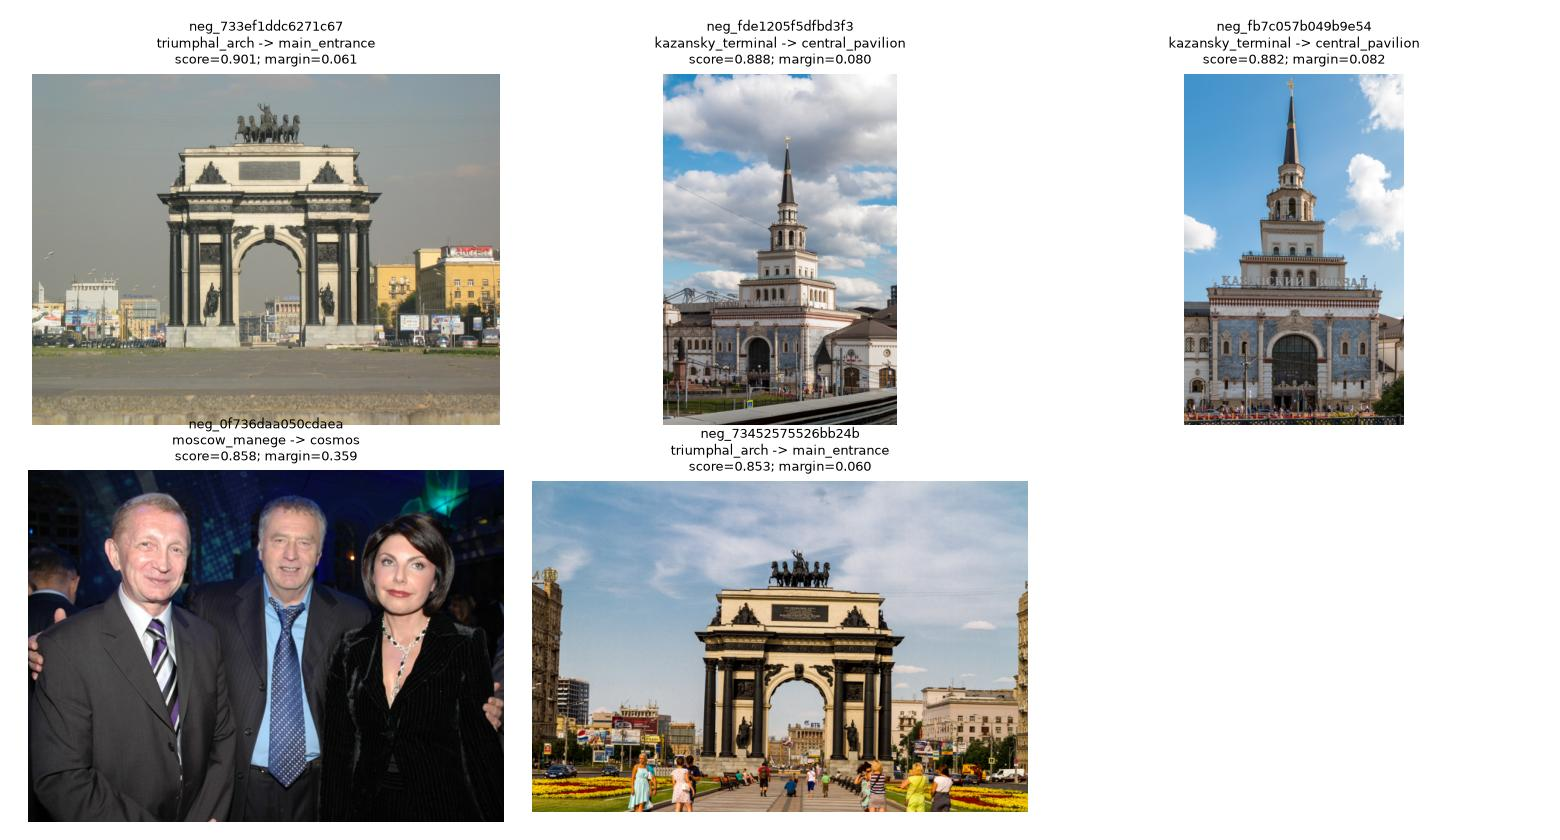

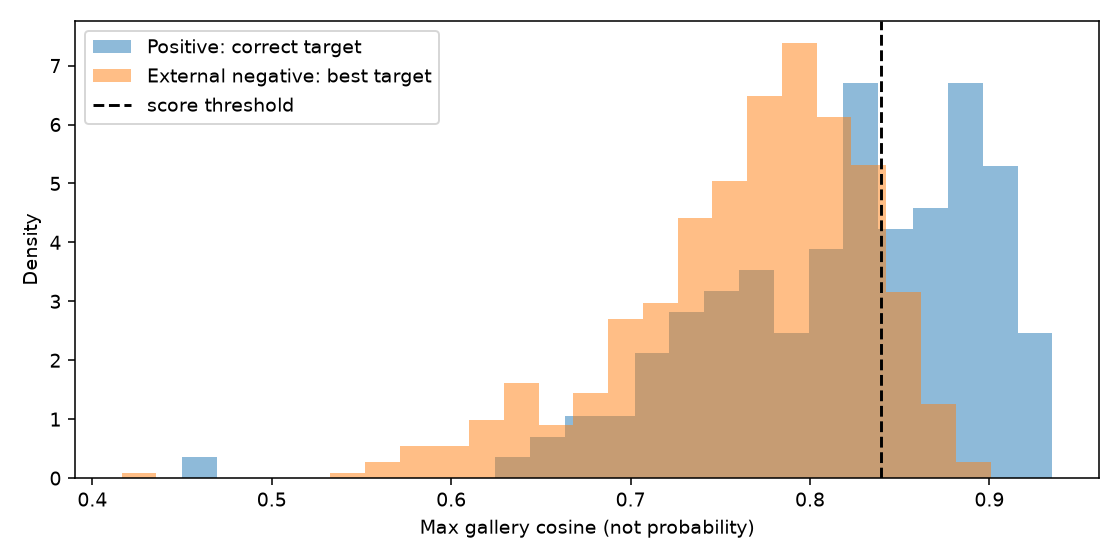

# MobileNetV3: отказ с проверенными external-negatives

Это экспериментальная политика отказа; автоматически вместо прежней версии не включается.

Backbone, 404 train-эталона и положительные splits сохранены; веса не дообучались. Предыдущий выпуск не изменён.
Новый выпуск: `models/baseline_mobilenetv3_negatives`; reference_version=64282c8db70a-37bbbca65dee.
Пороги: score ≥ 0.839531, margin ≥ 0.058894, margin > 0.
Подбор: только positive-val и negative-val; test в выборе порогов не участвует.

| Выборка | Фото | True accept | Known hard-wrong FAR | External any-POI FAR |
|---|---:|---:|---:|---:|
| positive-val | 151 | 31.79% | 0.00% | — |
| negative-val | 573 | — | — | 0.87% (5/573) |
| positive-test | 146 | 25.34% | 0.00% | — |
| negative-test | 573 | — | — | 0.87% (5/573) |

## Наблюдение → интерпретация → действие
- Из 1149 оставшихся negatives выпущено 1146; связей-кандидатов с положительным набором: 3 фото → подтверждение пользователя не устраняет технические пересечения → спорные кадры исключены; проверить negative_review_queue.csv.
- Negative val/test разделены по source POI и графу дубликатов → один посторонний объект не используется одновременно для настройки и оценки → сохранять выпущенные CSV неизменными.
- External any-POI FAR считает фото ошибочным при подтверждении хотя бы одной из 23 целей → это строже средней ошибки по всем целям → использовать его для основной оценки отказа, не маскировать ошибку множеством лёгких пар.
- Добавлены external-negatives → теперь измерен отказ на посторонних достопримечательностях Commons → не переносить результат на любую мобильную съёмку; дополнить полевыми negatives.
- Более строгий отказ может снизить true accept → настройка порогов не улучшает различимость POI → для 85% нужны новые положительные ракурсы и дообучение/сравнение эмбеддингов.
- Positive-test уже использовался для диагностики прежней версии → это сравнение на фиксированном диагностическом наборе → окончательное качество новой модели подтвердить на новом закрытом полевом test.
- Небольшие и зависимые внутри POI выборки → редкие ошибки оценены неточно → расширять число независимых POI и серий; не объявлять FAR гарантированным.
- source/author/licence сохранены в manifest, snapshots и prediction-таблицах → атрибуция доступна для каждого фото → сохранять её при дальнейших экспортах.

Цель 85% true accept не достигнута: на положительном test подтверждено 37/146 (25.34%). Ограничение отказа на внешних negatives требует улучшения эмбеддингов и новых независимых положительных фото; ослабление порогов текущего выпуска по test не выполнялось.


In [5]:
predictions=pd.read_csv(OUTPUT/'negative_test_predictions.csv',keep_default_na=False)
display(predictions[predictions.accepted_any_poi][['image_id','source_poi_id','predicted_poi_id','score','margin']])
display(pd.read_csv(OUTPUT/'negative_test_groups.csv'))
for name in ['negative_test_false_accepts.jpg','test_score_distribution.png']:
    path=ROOT/'reports/baseline_mobilenetv3_negatives'/name
    if path.exists():display(DisplayImage(filename=str(path)))
display(Markdown((ROOT/'reports/baseline_mobilenetv3_negatives/summary.md').read_text(encoding='utf-8')))


## 5. Проверка своей цели

Используйте новый каталог артефактов; предыдущая версия baseline сохранена отдельно.
Неизвестный target_poi_id возвращает target_poi_not_supported.


In [6]:
verifier=POIVerifier(OUTPUT)
example=negatives['test'].iloc[0]
display(pd.Series(verifier.verify(ROOT/example.file_path,verifier.poi_ids[0])))
# verifier.verify(Path('path/to/photo.jpg'),'moscow/ostankinskiy/ostankino_tower')


accepted                                                             False
reason                                                     poi_not_matched
target_poi_id                            moscow/arbat/arseny_morozov_house
predicted_poi_id                            moscow/tverskoy/hotel_metropol
score                                                             0.567577
margin                                                            -0.17686
score_is_probability                                                 False
reference_image_id                                     wm_6b5eee5f784ab493
reference_source                                         wikimedia_commons
reference_author                                                 User:Dims
reference_licence                                            Public domain
reference_version                                64282c8db70a-37bbbca65dee
threshold_version                                         914889fcf1aa5f6e
preprocessing_version    